In [1]:
import os
os.listdir()   # باید هم Preprocessing_TSFNet_paper_nback_v2.py هم qc_eog_threshold_validation.py رو ببینید

['.ipynb_checkpoints',
 'crash_safe_logger.py',
 'New folder',
 'output_log_bands.txt',
 'Preprocessing_TSFNet_paper_nback.py',
 'Preprocessing_TSFNet_paper_nback0.py',
 'Preprocessing_TSFNet_paper_nback_v2.py',
 'qc_eog_threshold_validation.py',
 'run_all_subjects.py',
 'tsfnet_model_notebook.py',
 'tsfnet_model_notebook0.py',
 'Untitled.ipynb',
 'Untitled1.ipynb',
 'Untitled2.ipynb',
 'Untitled3.ipynb',
 '__pycache__']

In [1]:
%run qc_eog_threshold_validation.py --n_workers 5

Parsed 26 subjects from log. 0 removed ZERO ocular components: []

=== Running EOG threshold QC on: ['VP011', 'VP020', 'VP021', 'VP023', 'VP001'] (n_workers=5) ===

Score summary table saved to: E:\kntu\Thesis\codes\Results\TSFNET_PAPER_EXACT_nback\eog_threshold_qc\eog_ic_scores_summary.csv
Starter decision file saved to: E:\kntu\Thesis\codes\Results\TSFNET_PAPER_EXACT_nback\eog_threshold_qc\subject_specific_eog_thresholds.STARTER.json

Next step: open the per-subject QC PNGs + the CSV, decide per subject, fill in 'suggested_threshold' + 'reason' in the STARTER json, then rename it to subject_specific_eog_thresholds.json for the main pipeline to consume.


In [2]:
import pandas as pd
df = pd.read_csv(r"E:\kntu\Thesis\codes\Results\TSFNET_PAPER_EXACT_nback\eog_threshold_qc\eog_ic_scores_summary.csv")
print(df.shape)
print(df["subject_id"].unique())   # باید هر ۵ subject رو نشون بده

(108, 6)
<StringArray>
['VP011', 'VP020', 'VP021', 'VP023', 'VP001']
Length: 5, dtype: str


In [3]:
df["subject_id"].value_counts()

subject_id
VP011    30
VP023    24
VP021    20
VP001    18
VP020    16
Name: count, dtype: int64

In [4]:
borderline = df[(df["abs_score"] >= 1.5) & (df["abs_score"] <= 2.5)]
print(f"تعداد کل ردیف‌های borderline: {len(borderline)}")
print(borderline.sort_values("abs_score", ascending=False))

تعداد کل ردیف‌های borderline: 0
Empty DataFrame
Columns: [subject_id, ic_index, eog_channel, score, abs_score, currently_excluded]
Index: []


In [5]:
excluded_counts = df.groupby("subject_id")["currently_excluded"].sum()
print(excluded_counts)

subject_id
VP001    6
VP011    8
VP020    4
VP021    4
VP023    4
Name: currently_excluded, dtype: int64


In [6]:
%run qc_eog_fast_full_check.py --n_workers 5


=== FAST FULL EOG CHECK on 26 subjects, n_workers=5 ===


Full summary saved: E:\kntu\Thesis\codes\Results\TSFNET_PAPER_EXACT_nback\eog_fast_full_check\full_check_summary.csv

=== 20 / 26 subjects FLAGGED for review ===
subject_id  n_ics  n_excluded  pct_excluded  n_corr_only  n_iclabel_only  n_both
     VP001      9           4          44.4            0               1       3
     VP003     11           4          36.4            0               2       2
     VP004     15           5          33.3            0               1       4
     VP005     10           5          50.0            0               1       4
     VP006      9           4          44.4            0               2       2
     VP008      6           2          33.3            0               0       2
     VP009      6           3          50.0            0               1       2
     VP010     11           3          27.3            1               1       1
     VP011     15           5          33.3       

In [7]:
import pandas as pd
df = pd.read_csv(r"E:\kntu\Thesis\codes\Results\TSFNET_PAPER_EXACT_nback\eog_fast_full_check\full_check_summary.csv")
flagged = df[df["needs_review"]]
print(flagged[["subject_id", "pct_excluded", "n_corr_only", "n_iclabel_only", "n_both"]])

   subject_id  pct_excluded  n_corr_only  n_iclabel_only  n_both
0       VP001          44.4            0               1       3
2       VP003          36.4            0               2       2
3       VP004          33.3            0               1       4
4       VP005          50.0            0               1       4
5       VP006          44.4            0               2       2
7       VP008          33.3            0               0       2
8       VP009          50.0            0               1       2
9       VP010          27.3            1               1       1
10      VP011          33.3            1               1       3
12      VP013          33.3            0               0       2
13      VP014          50.0            0               1       2
14      VP015          28.6            0               0       2
15      VP016          50.0            0               2       0
16      VP017          35.7            0               3       2
17      VP018          36

E:\kntu\Thesis\codes\Results\TSFNET_PAPER_EXACT_nback\eog_fast_full_check/VP010\VP010_CORRONLY_ic8_properties.png


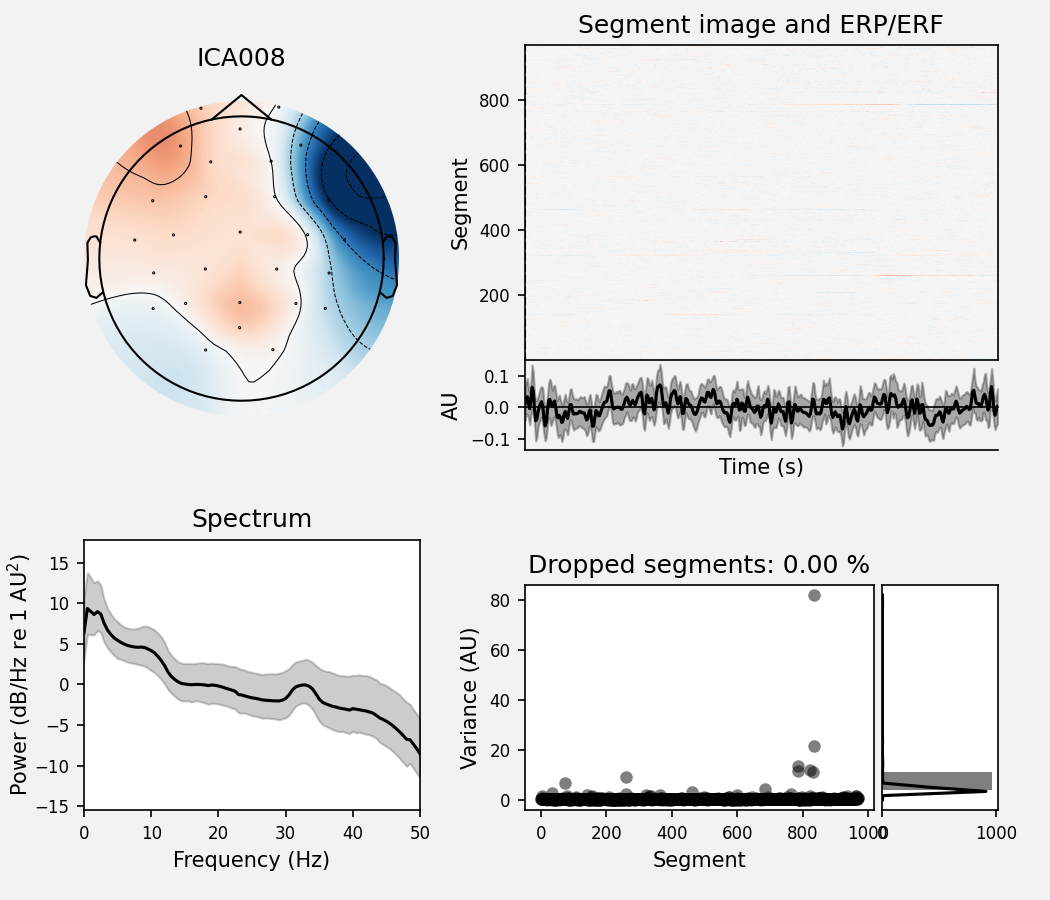

E:\kntu\Thesis\codes\Results\TSFNET_PAPER_EXACT_nback\eog_fast_full_check/VP010\VP010_CORRONLY_topo_0.png


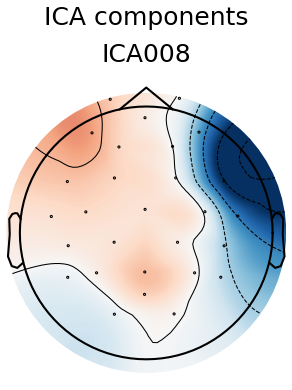

E:\kntu\Thesis\codes\Results\TSFNET_PAPER_EXACT_nback\eog_fast_full_check/VP011\VP011_CORRONLY_ic6_properties.png


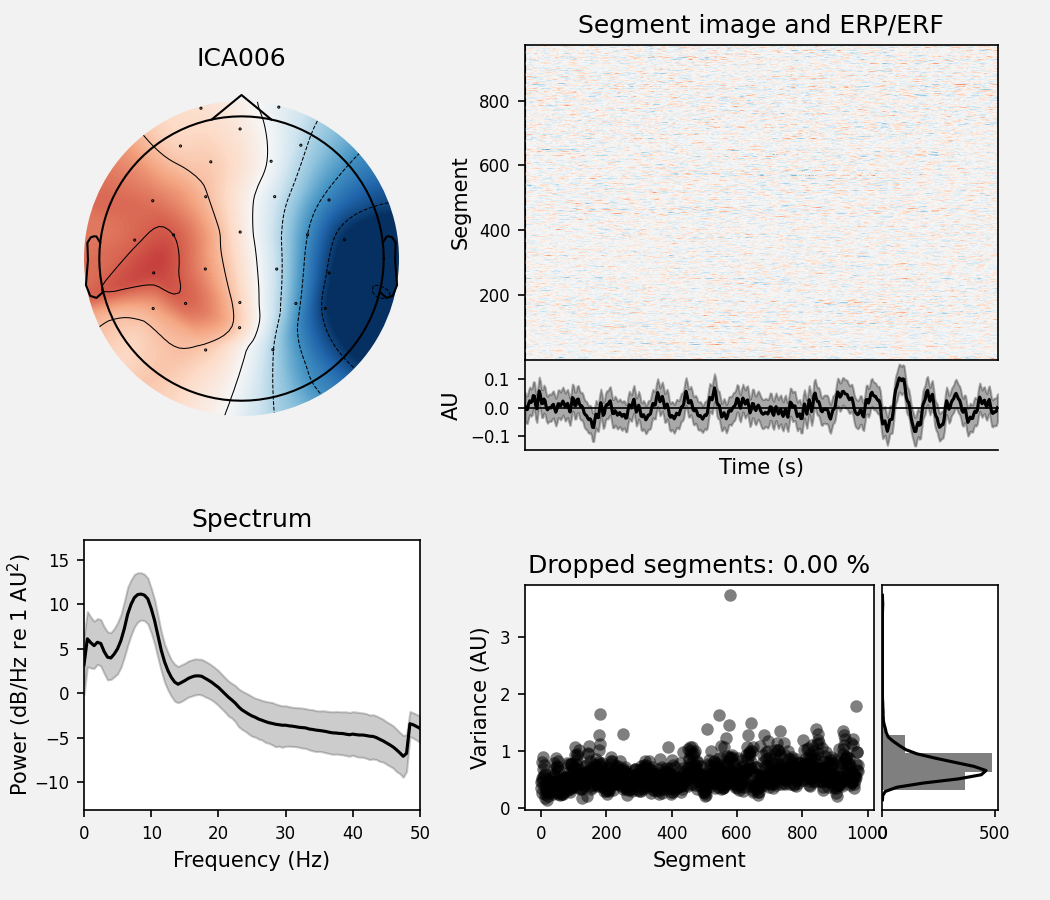

E:\kntu\Thesis\codes\Results\TSFNET_PAPER_EXACT_nback\eog_fast_full_check/VP011\VP011_CORRONLY_topo_0.png


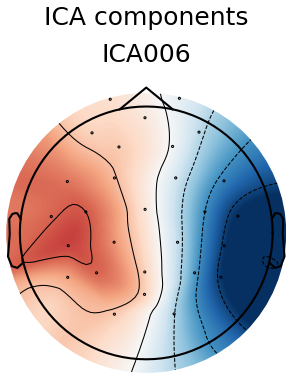

E:\kntu\Thesis\codes\Results\TSFNET_PAPER_EXACT_nback\eog_fast_full_check/VP018\VP018_CORRONLY_ic4_properties.png


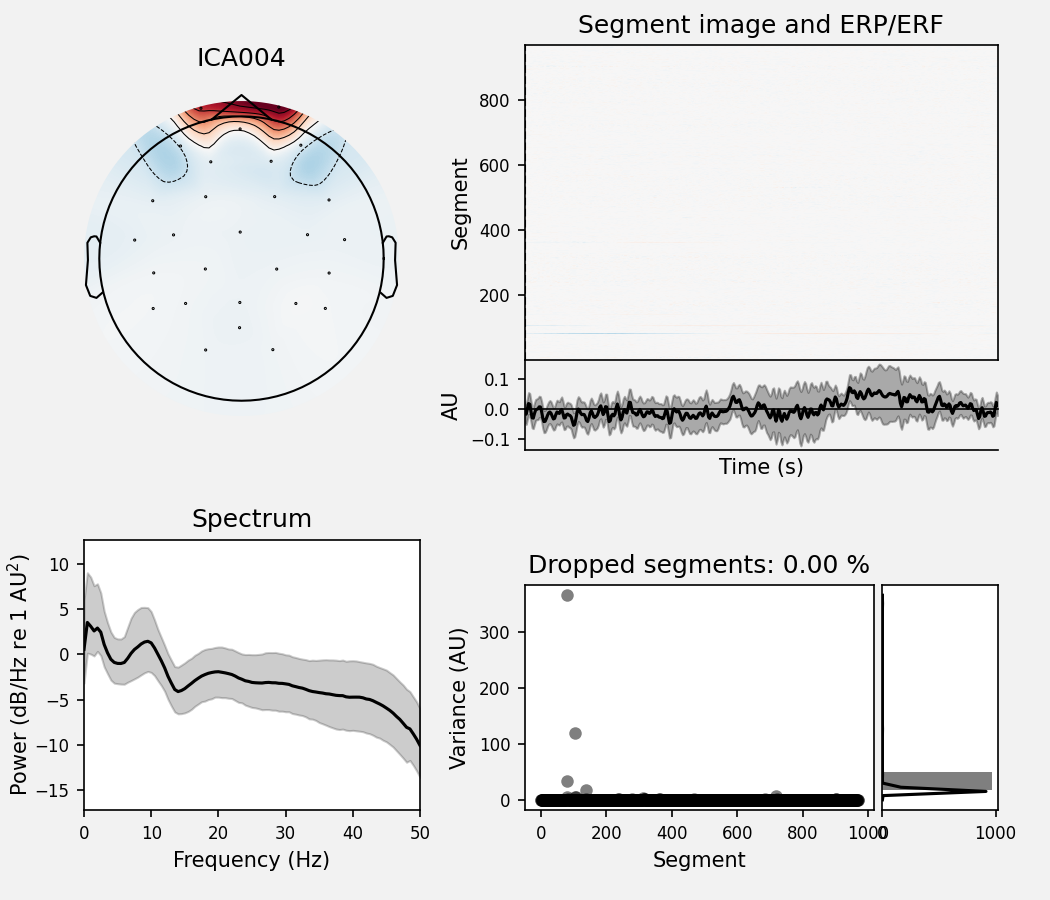

E:\kntu\Thesis\codes\Results\TSFNET_PAPER_EXACT_nback\eog_fast_full_check/VP018\VP018_CORRONLY_topo_0.png


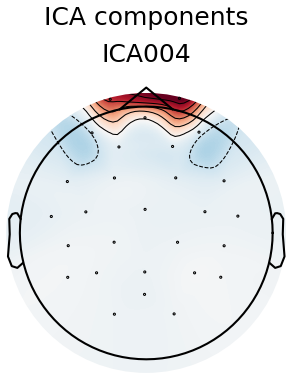

E:\kntu\Thesis\codes\Results\TSFNET_PAPER_EXACT_nback\eog_fast_full_check/VP022\VP022_CORRONLY_ic6_properties.png


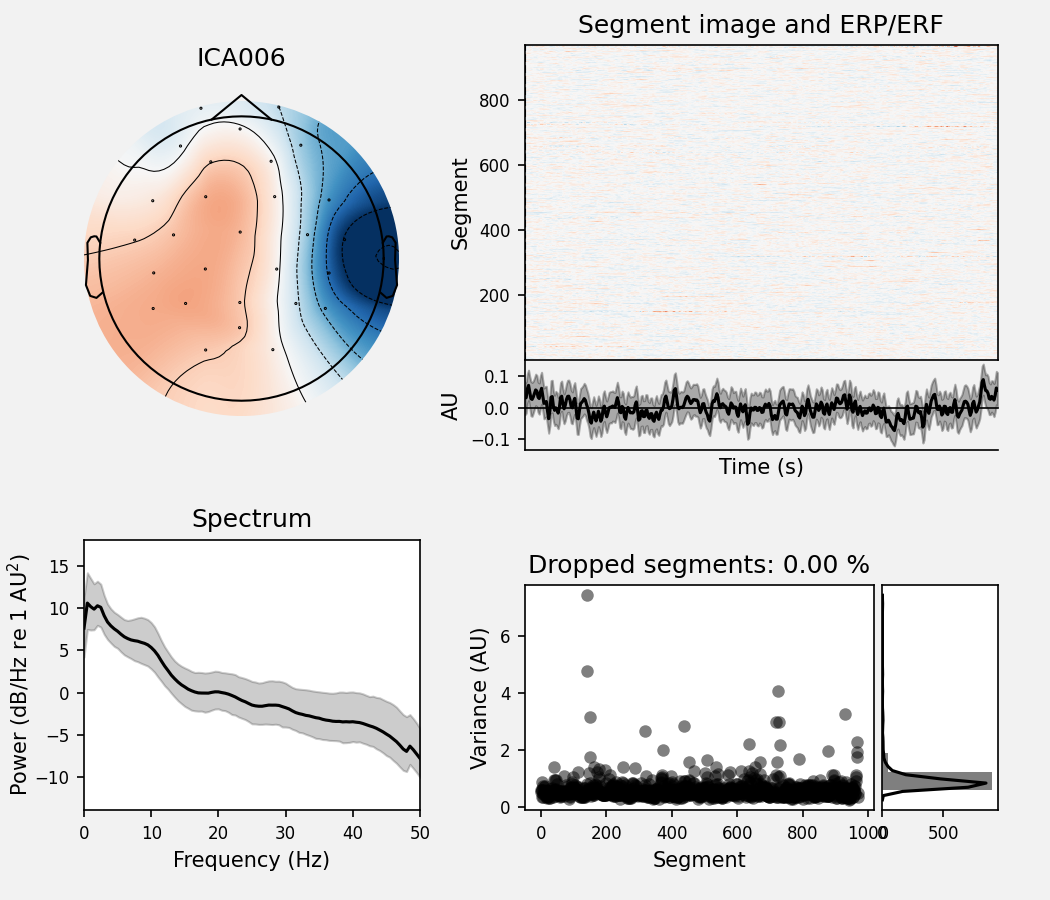

E:\kntu\Thesis\codes\Results\TSFNET_PAPER_EXACT_nback\eog_fast_full_check/VP022\VP022_CORRONLY_topo_0.png


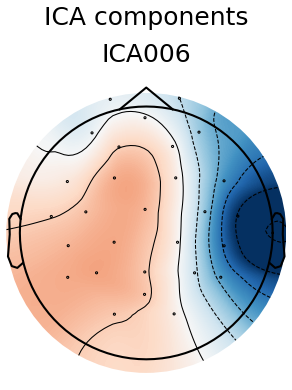

In [8]:
from PIL import Image
import glob
qc_dir = r"E:\kntu\Thesis\codes\Results\TSFNET_PAPER_EXACT_nback\eog_fast_full_check"
for sid in ["VP010", "VP011", "VP018", "VP022"]:
    for f in sorted(glob.glob(f"{qc_dir}/{sid}/*.png")):
        print(f); display(Image.open(f))

In [9]:
df = pd.read_csv(r"E:\kntu\Thesis\codes\Results\TSFNET_PAPER_EXACT_nback\eog_fast_full_check\full_check_summary.csv")
print(df[["subject_id", "n_ics"]].sort_values("n_ics"))

   subject_id  n_ics
15      VP016      4
24      VP025      5
8       VP009      6
7       VP008      6
13      VP014      6
12      VP013      6
14      VP015      7
19      VP020      8
18      VP019      9
25      VP026      9
5       VP006      9
0       VP001      9
4       VP005     10
20      VP021     10
2       VP003     11
9       VP010     11
17      VP018     11
1       VP002     12
6       VP007     12
11      VP012     12
22      VP023     12
16      VP017     14
10      VP011     15
3       VP004     15
21      VP022     16
23      VP024     17


In [10]:
%run qc_eog_fast_full_check.py --n_workers 5


=== FAST FULL EOG CHECK on 26 subjects, n_workers=5 ===



AttributeError: module '__main__' has no attribute '__spec__'

In [11]:
with open(r"E:\kntu\Thesis\codes\HOPE-LAST-CODE-FILE\new-tsfnet\output_log_QC_bands.txt", encoding="utf-8") as f:
    log_text = f.read()
print(log_text)

--- VP003 (PID 4636) ---
[2026-08-15 15:53:43] [PID4636]   EEG channel check: 30 total in cnt.clab, 28 non-EOG (scalp) channels, TP9/TP10 present=False (expected: 28 channels, False -- confirmed via VP001).
Fitting ICA to data using 28 channels (please be patient, this may take a while)
--- VP007 (PID 8940) ---
[2026-08-15 15:53:43] [PID8940]   EEG channel check: 30 total in cnt.clab, 28 non-EOG (scalp) channels, TP9/TP10 present=False (expected: 28 channels, False -- confirmed via VP001).
Fitting ICA to data using 28 channels (please be patient, this may take a while)
--- VP009 (PID 7192) ---
[2026-08-15 15:53:43] [PID7192]   EEG channel check: 30 total in cnt.clab, 28 non-EOG (scalp) channels, TP9/TP10 present=False (expected: 28 channels, False -- confirmed via VP001).
Fitting ICA to data using 28 channels (please be patient, this may take a while)
--- VP005 (PID 20576) ---
[2026-08-15 15:53:43] [PID20576]   EEG channel check: 30 total in cnt.clab, 28 non-EOG (scalp) channels, TP9/T

In [12]:
for line in log_text.splitlines():
    if "AMBIGUOUS" in line or "FLAGGED" in line or "veto totals" in line:
        print(line)

  [VP009] n_ics=6, excluded(post-veto)=3 (50.0%), corr_only=0 (auto_unexcluded=0, ambiguous=0), iclabel_only=1, both=2, FLAGGED=True
  [VP001] n_ics=9, excluded(post-veto)=4 (44.4%), corr_only=0 (auto_unexcluded=0, ambiguous=0), iclabel_only=1, both=3, FLAGGED=True
  [VP007] n_ics=12, excluded(post-veto)=2 (16.7%), corr_only=1 (auto_unexcluded=1, ambiguous=0), iclabel_only=0, both=2, FLAGGED=False
  [VP005] n_ics=10, excluded(post-veto)=5 (50.0%), corr_only=0 (auto_unexcluded=0, ambiguous=0), iclabel_only=1, both=4, FLAGGED=True
  [VP008] n_ics=6, excluded(post-veto)=2 (33.3%), corr_only=0 (auto_unexcluded=0, ambiguous=0), iclabel_only=0, both=2, FLAGGED=True
  [VP010] n_ics=11, excluded(post-veto)=3 (27.3%), corr_only=1 (auto_unexcluded=0, ambiguous=0), iclabel_only=1, both=1, FLAGGED=True
  [VP003] n_ics=11, excluded(post-veto)=4 (36.4%), corr_only=0 (auto_unexcluded=0, ambiguous=0), iclabel_only=2, both=2, FLAGGED=True
  [VP006] n_ics=9, excluded(post-veto)=4 (44.4%), corr_only=0 (a

E:\kntu\Thesis\codes\Results\TSFNET_PAPER_EXACT_nback\eog_fast_full_check/VP012\VP012_AMBIGUOUS_ic6_properties.png


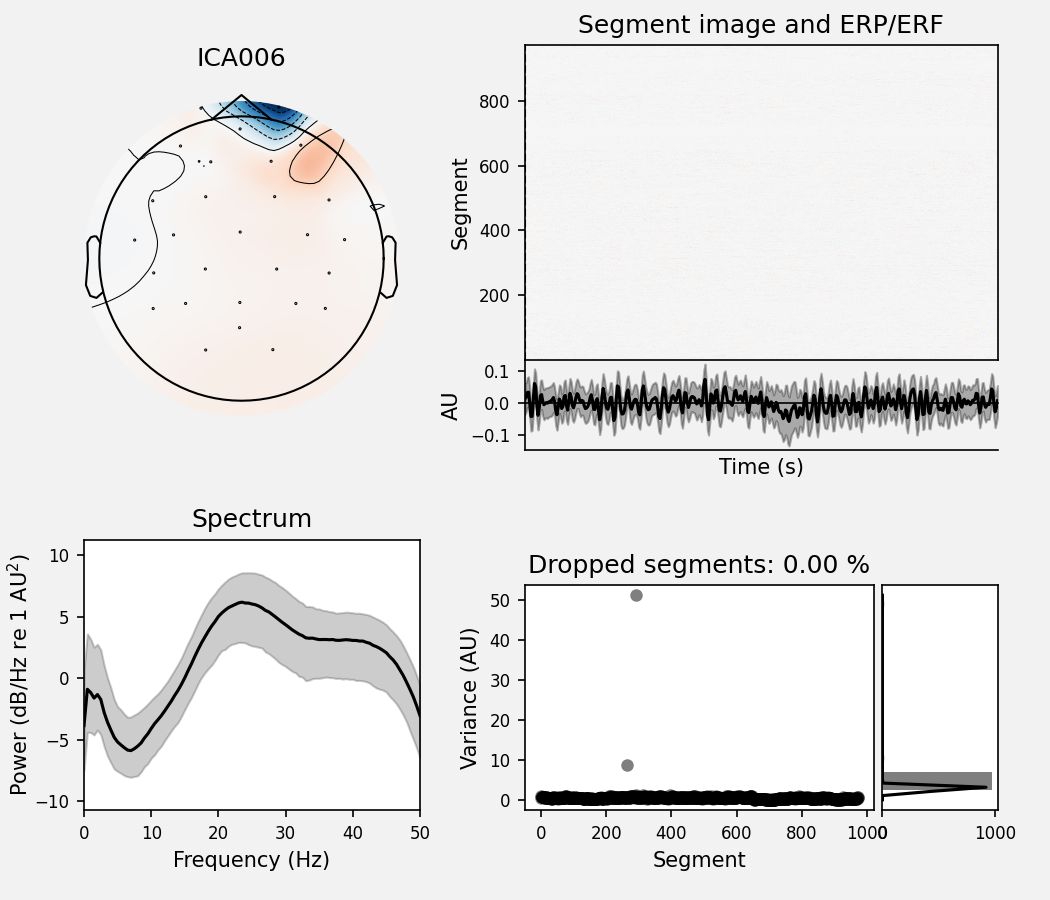

E:\kntu\Thesis\codes\Results\TSFNET_PAPER_EXACT_nback\eog_fast_full_check/VP012\VP012_AMBIGUOUS_topo_0.png


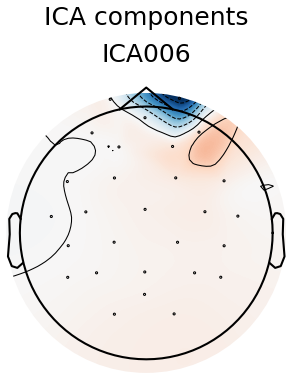

E:\kntu\Thesis\codes\Results\TSFNET_PAPER_EXACT_nback\eog_fast_full_check/VP022\VP022_AMBIGUOUS_ic6_properties.png


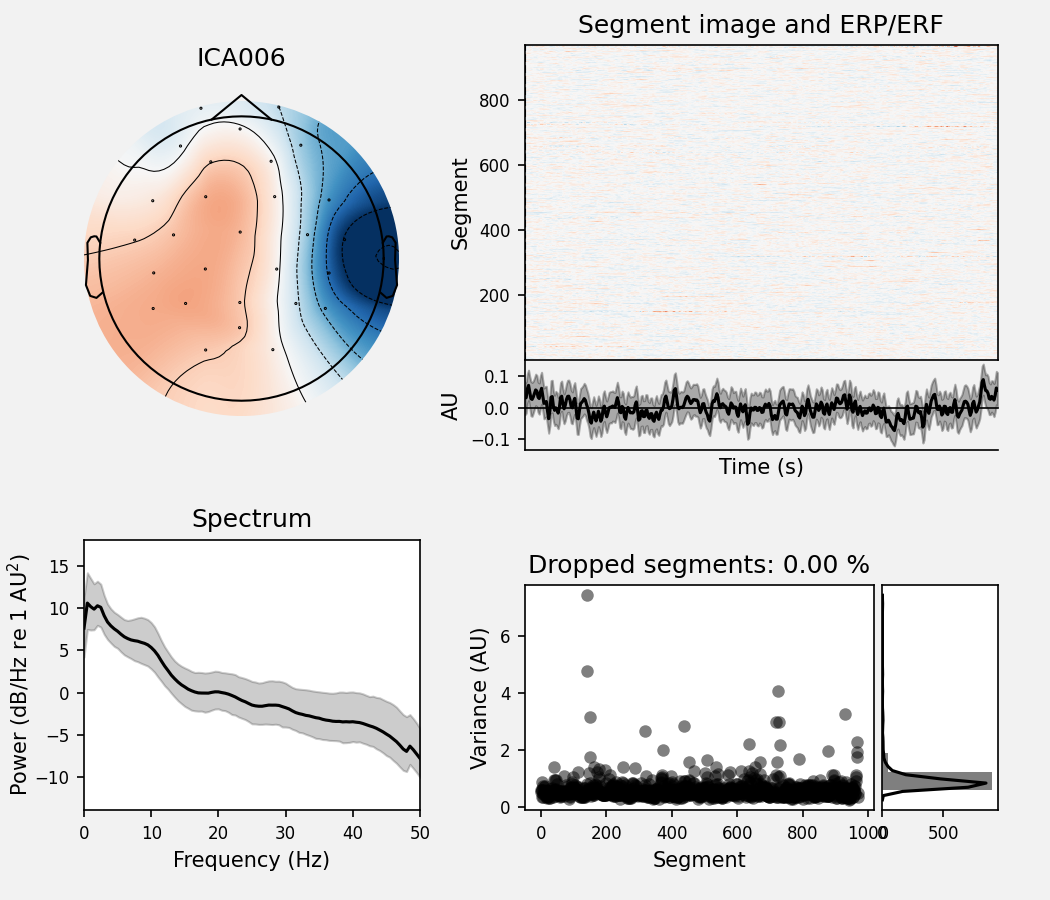

E:\kntu\Thesis\codes\Results\TSFNET_PAPER_EXACT_nback\eog_fast_full_check/VP022\VP022_AMBIGUOUS_topo_0.png


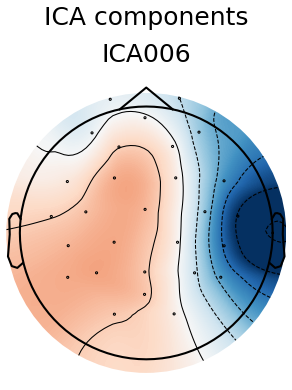

E:\kntu\Thesis\codes\Results\TSFNET_PAPER_EXACT_nback\eog_fast_full_check/VP022\VP022_CORRONLY_ic6_properties.png


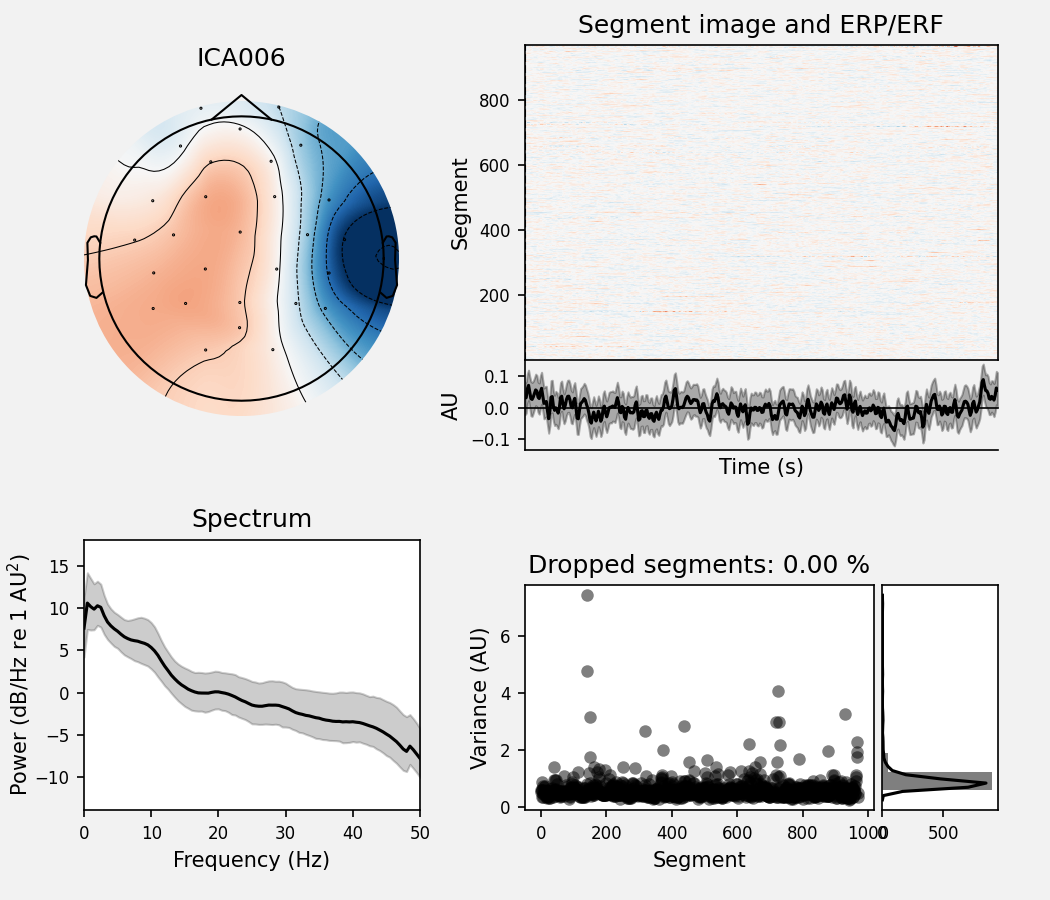

E:\kntu\Thesis\codes\Results\TSFNET_PAPER_EXACT_nback\eog_fast_full_check/VP022\VP022_CORRONLY_topo_0.png


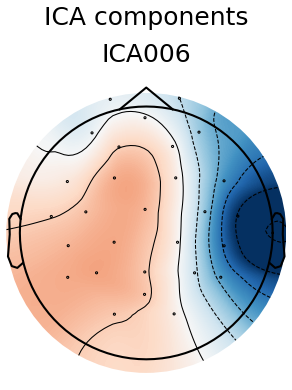

In [13]:
from PIL import Image
import glob
qc_dir = r"E:\kntu\Thesis\codes\Results\TSFNET_PAPER_EXACT_nback\eog_fast_full_check"
for sid in ["VP012", "VP022"]:
    for f in sorted(glob.glob(f"{qc_dir}/{sid}/*.png")):
        print(f); display(Image.open(f))

In [16]:
%run test_iclabel_dual_filter.py --subjects VP010 --n_workers 1


=== Comparing OLD vs NEW (dual-filter) ICA pipeline on: ['VP010'] ===

--- VP010 (PID 1580) ---
[2026-08-15 16:43:28] [PID1580]   EEG channel check: 30 total in cnt.clab, 28 non-EOG (scalp) channels, TP9/TP10 present=False (expected: 28 channels, False -- confirmed via VP001).
Fitting ICA to data using 28 channels (please be patient, this may take a while)
Selecting by explained variance: 11 components
Fitting ICA took 31.5s.
  [VP010] NEW pipeline FAILED: lowpass frequency 100.0 must be less than Nyquist (100.0)
  [VP010] traceback:
Traceback (most recent call last):
  File "E:\kntu\Thesis\codes\HOPE-LAST-CODE-FILE\new-tsfnet\test_iclabel_dual_filter.py", line 179, in process_subject_compare
    new_result = run_new_pipeline(raw_before, filtered_analysis, picks_eeg)
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "E:\kntu\Thesis\codes\HOPE-LAST-CODE-FILE\new-tsfnet\test_iclabel_dual_filter.py", line 104, in run_new_pipeline
    filtered_iclabel = bu

In [17]:
%run test_iclabel_dual_filter.py --subjects VP010 --n_workers 1


=== Comparing OLD vs NEW (dual-filter) ICA pipeline on: ['VP010'] ===

--- VP010 (PID 1580) ---
[2026-08-15 16:51:16] [PID1580]   EEG channel check: 30 total in cnt.clab, 28 non-EOG (scalp) channels, TP9/TP10 present=False (expected: 28 channels, False -- confirmed via VP001).
Fitting ICA to data using 28 channels (please be patient, this may take a while)
Selecting by explained variance: 11 components
Fitting ICA took 33.0s.
Fitting ICA to data using 28 channels (please be patient, this may take a while)
Selecting by explained variance: 7 components
Fitting ICA took 25.4s.
  [VP010] OLD: excluded=[np.int64(1), 7, np.int64(8)] (27.3%)
  [VP010] NEW (eye-only):    excluded=[np.int64(2), np.int64(6)] (28.6%)
  [VP010] NEW (all classes): excluded=[0, 1, np.int64(2), 3, np.int64(6)] (71.4%)

Comparison table saved: E:\kntu\Thesis\codes\Results\TSFNET_PAPER_EXACT_nback\iclabel_dual_filter_test\old_vs_new_comparison.csv
subject_id  n_ics  OLD_pct_excluded  NEW_eyeonly_pct_excluded  NEW_allc

In [14]:
%run test_iclabel_dual_filter.py --subjects VP010,VP011,VP018 --n_workers 1


=== Comparing OLD vs NEW (dual-filter) ICA pipeline on: ['VP010', 'VP011', 'VP018'] ===

--- VP010 (PID 1580) ---
[2026-08-15 16:27:38] [PID1580]   EEG channel check: 30 total in cnt.clab, 28 non-EOG (scalp) channels, TP9/TP10 present=False (expected: 28 channels, False -- confirmed via VP001).
Fitting ICA to data using 28 channels (please be patient, this may take a while)
Selecting by explained variance: 11 components
Fitting ICA took 33.4s.
  [VP010] OLD: excluded=[np.int64(1), 7, np.int64(8)] (27.3%)
  [VP010] NEW (eye-only):    excluded=None (None%)
  [VP010] NEW (all classes): excluded=None (None%)
--- VP011 (PID 1580) ---
[2026-08-15 16:28:21] [PID1580]   EEG channel check: 30 total in cnt.clab, 28 non-EOG (scalp) channels, TP9/TP10 present=False (expected: 28 channels, False -- confirmed via VP001).
Fitting ICA to data using 28 channels (please be patient, this may take a while)
Selecting by explained variance: 15 components
Fitting ICA took 213.7s.
  [VP011] OLD: excluded=[np